# 02 - Data preparation, feature engineering and selection
CRISP-DM phase 3. Preprocessing lives in `src/preprocessing/pipeline.py` (fit per CV fold, never on all data); this notebook shows the reasoning and the evidence.

In [1]:
import json, sys, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
sys.path.insert(0, str(Path.cwd()))
from src.config import load_settings
from src.data.loader import load_sessions, stratified_split
from src.features.engineering import add_engineered_features
from src.utils import metrics as M
S = load_settings()
df = load_sessions(S)

In [2]:
from src.preprocessing.pipeline import build_preprocessor
from src.models.trainer import build_registry, SessionClassifier
from src.models.evaluation import cross_validate
train, test = stratified_split(df, S)
y = train.Converted.to_numpy()
pre = build_preprocessor(S).fit(train)
print('input columns the model needs:', pre.input_columns)
print('expanded model features:', len(pre.feature_names_))
print('PageValues used:', 'PageValues' in pre.input_columns)

input columns the model needs: ['Administrative', 'Administrative_Duration', 'BounceRates', 'Browser', 'ExitRates', 'Informational', 'Informational_Duration', 'Month', 'OperatingSystems', 'ProductRelated', 'ProductRelated_Duration', 'Region', 'SpecialDay', 'TrafficType', 'VisitorType', 'Weekend']
expanded model features: 79
PageValues used: False


**Takeaway:** 16 raw inputs; PageValues deliberately absent. Categoricals (including OperatingSystems / Browser / Region / TrafficType) become one-hot columns; unseen categories at serving time map to all zeros.

In [3]:
e = add_engineered_features(train)
eng = ['total_pages','total_duration','avg_time_per_page','product_page_share','time_per_product_page']
print(e[eng + ['Converted']].corr()['Converted'].drop('Converted').round(3))

total_pages              0.478
total_duration           0.302
avg_time_per_page        0.008
product_page_share       0.147
time_per_product_page    0.001
Name: Converted, dtype: float64


**Takeaway:** the engineered ratios are easy to explain to a stakeholder (how deep, how long, how product-focused). Their value is judged by an ablation below, not assumed.

In [4]:
spec = build_registry()['LogisticRegression']
import src.preprocessing.pipeline as P
base = P.LOG_COLS_BASE.copy(), P.PLAIN_COLS_BASE.copy()
def cv_with(logc, plainc):
    P.LOG_COLS_BASE[:] = logc; P.PLAIN_COLS_BASE[:] = plainc
    try:
        r = cross_validate(spec, S, train, y, 'none', {'C': 0.03})
    finally:
        P.LOG_COLS_BASE[:] = base[0]; P.PLAIN_COLS_BASE[:] = base[1]
    return r
raw_log = [c for c in base[0] if c not in eng]; raw_plain = [c for c in base[1] if c not in eng]
a = cv_with(base[0], base[1]); b = cv_with(raw_log, raw_plain)
pd.DataFrame({'features': ['raw + engineered', 'raw only'], 'CV PR-AUC': [a['pr_auc_mean'], b['pr_auc_mean']], 'std': [a['pr_auc_std'], b['pr_auc_std']],
              'CV ROC-AUC': [a['roc_auc_mean'], b['roc_auc_mean']]}).round(4)

,features,CV PR-AUC,std,CV ROC-AUC
0,raw + engineered,0.5313,0.0281,0.8315
1,raw only,0.5307,0.0278,0.8315


**Takeaway:** the engineered ratios add 0.0006 CV PR-AUC (0.5313 vs 0.5307), far inside one fold-to-fold standard deviation (0.028). They are **not shown to improve prediction**; a logistic model on log-counts can already form most of these combinations. They are kept because they are easy to explain to a stakeholder, not because they win.

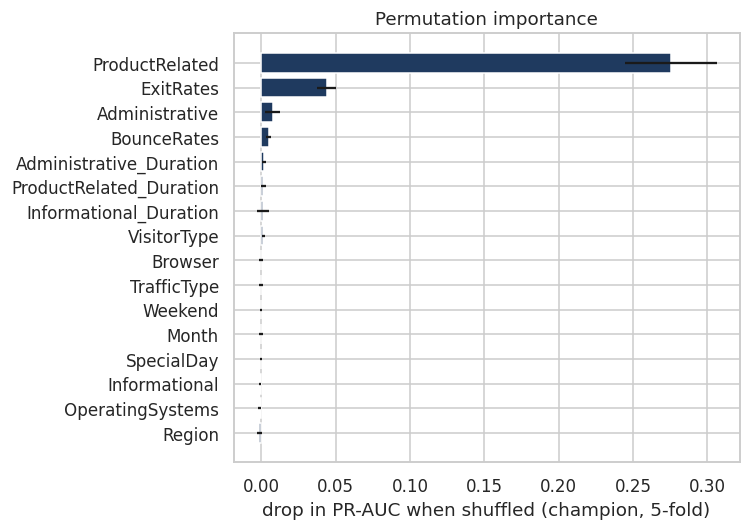

,feature,mean_drop,std_drop,folds_positive
0,ProductRelated,0.2755,0.0308,5
1,ExitRates,0.0441,0.0063,5
2,Administrative,0.0076,0.0051,4
3,BounceRates,0.0049,0.0018,5
4,Administrative_Duration,0.0018,0.0014,5
5,ProductRelated_Duration,0.0014,0.0016,5
6,Informational_Duration,0.0013,0.0041,3
7,VisitorType,0.0013,0.0011,4
8,Browser,0.0001,0.0013,3
9,TrafficType,-0.0002,0.0013,2


In [5]:
pi = pd.DataFrame(json.load(open(S.path('model_dir') / 'metrics.json'))['permutation_importance'])
fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(pi.feature[::-1], pi.mean_drop[::-1], xerr=pi.std_drop[::-1], color='#1F3A5F'); ax.set_xlabel('drop in PR-AUC when shuffled (champion, 5-fold)'); ax.set_title('Permutation importance')
plt.tight_layout(); plt.show()
pi.round(4)

**Takeaway:** ProductRelated (0.28) dwarfs everything; ExitRates (0.04) is second; everything else is at or below noise. Lens 2 (Shapley) is in notebook 04 and agrees on the ranking (Spearman 0.89).

In [6]:
fs = json.load(open(S.path('model_dir') / 'metrics.json'))['feature_selection']
print(json.dumps(fs, indent=1))

{
 "dropped": [
  "TrafficType",
  "Weekend",
  "Month",
  "SpecialDay",
  "OperatingSystems",
  "Region"
 ],
 "pr_auc_full": 0.5313382103079364,
 "pr_auc_selected": 0.5376019576560818,
 "pr_auc_full_std": 0.028060750786144322,
 "pr_auc_selected_std": 0.024490482714631258,
 "rule": "drop a categorical/rate input if shuffling it costs < 0.001 PR-AUC and hurts in <= half of the folds",
 "applied": true
}


**Selection result:** inputs that do not earn their place (shuffling costs < 0.001 PR-AUC and hurts in at most half the folds) were removed, and the reduced set was kept only because CV PR-AUC did not drop. The change in CV PR-AUC is within noise: the claim is "no loss with fewer inputs", not "improvement". Note that Month is among the removed inputs even though raw conversion differs by month: once browsing behaviour is known, month adds nothing measurable.